

**Membres du binôme :** Miloud Meziane
**Date :** 11/12/2025



## 0. Configuration de l'environnement

Pour réaliser ce TP, nous utilisons l'écosystème Python scientifique standard.
Nous importons ici l'ensemble des librairies nécessaires :
* **Pandas et Numpy** : Pour la manipulation de données (DataFrames, matrices).
* **Matplotlib** : Pour la visualisation graphique (courbes ROC, histogrammes).
* **Scikit-Learn** : Pour l'ensemble des algorithmes d'apprentissage (Classification, Preprocessing, Validation).

Nous configurons également l'environnement pour améliorer la lisibilité des sorties (suppression de la notation scientifique et des avertissements non critiques).

In [38]:
%%writefile utils.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import pickle

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_selection import RFE   
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, roc_curve, make_scorer
)


warnings.filterwarnings("ignore")
np.set_printoptions(threshold=10000, suppress=True)

# ------------------------------------------------------------
# 0. CHARGEMENT ET SPLIT
# ------------------------------------------------------------

def load_and_split_data(filename, sep=';'):
    try:
        df = pd.read_csv(filename, sep=sep)
    except:
        df = pd.read_csv(filename, sep=',')
    data = df.values
    X = data[:, :-1].astype(float)
    y = data[:, -1].astype(float)
    n_pos = np.sum(y == 1)
    n_neg = np.sum(y == 0)
    print(f"Dataset : {df.shape}")
    print(f"Répartition : {n_pos} Positifs ({n_pos/len(y):.2%}) / {n_neg} Négatifs")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.5, random_state=1, stratify=y
    )
    return X_train, X_test, y_train, y_test, df


# ------------------------------------------------------------
# 1. COMPARAISON DES CLASSIFIEURS (Q2)
# ------------------------------------------------------------

def evaluation(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
    except:
        y_proba = y_pred

    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)

    best_criteria = prec
    score_final = (acc + best_criteria) / 2

    print(f"\n--- {model_name} ---")
    print(f"Matrice :\n{cm}")
    print(f"Accuracy : {acc:.3f} | Précision : {prec:.3f} | Rappel : {rec:.3f}")
    print(f"AUC : {auc:.3f}")
    print(f"👉 Score Final : {score_final:.3f}")

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.2f})")

    return score_final


def run_classifiers_train_test(classifiers, X_train, y_train, X_test, y_test):
    results = {}
    best_score = 0
    best_model_obj = None
    best_model_name = ""

    plt.figure(figsize=(8, 6))
    for name, model in classifiers.items():
        model.fit(X_train, y_train)
        score = evaluation(model, X_test, y_test, name)
        results[name] = score
        if score > best_score:
            best_score = score
            best_model_obj = model
            best_model_name = name

    plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire')
    plt.title("Comparaison des Courbes ROC")
    plt.xlabel("Taux de Faux Positifs")
    plt.ylabel("Taux de Vrais Positifs")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"\n🏆 Le meilleur modèle est : {best_model_name} avec un score de {best_score:.3f}")
    return best_model_obj, results


# ------------------------------------------------------------
# 2. NORMALISATION (Q3)
# ------------------------------------------------------------

def run_normalization_and_compare(X_train, X_test, y_train, y_test, classifiers):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print("\n" + "="*50)
    print("COMPARAISON APRÈS NORMALISATION")
    print("="*50)

    best, scores = run_classifiers_train_test(
        classifiers, X_train_scaled, y_train, X_test_scaled, y_test
    )
    return X_train_scaled, X_test_scaled


# ------------------------------------------------------------
# 3. ACP + CONCAT (Q4)
# ------------------------------------------------------------

def enrichir_donnees(X_train_sc, X_test_sc):
    print("--- Calcul ACP et Concaténation ---")
    pca = PCA(n_components=3)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)
    X_train_final = np.hstack([X_train_sc, X_train_pca])
    X_test_final = np.hstack([X_test_sc, X_test_pca])
    print(f"✅ Dimensions après concaténation : {X_train_final.shape} (16 variables)")
    return X_train_final, X_test_final


# ------------------------------------------------------------
# 4. SÉLECTION DE VARIABLES (Q5)
# ------------------------------------------------------------

def calcul_importance_variables(Xtrain, Ytrain, nom_cols):
    print("\n--- 1. Importance (RF) ---")
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(Xtrain, Ytrain)
    importances = clf.feature_importances_
    sorted_idx = np.argsort(importances)[::-1]

    print("Top 5 variables :", nom_cols[sorted_idx[:5]])

    padding = np.arange(Xtrain.shape[1]) + 0.5
    plt.figure(figsize=(10, 8))
    plt.barh(padding, importances[sorted_idx], align='center')
    plt.yticks(padding, nom_cols[sorted_idx])
    plt.xlabel("Importance Relative")
    plt.title("Importance (avec ACP)")
    plt.gca().invert_yaxis()
    plt.show()
    return sorted_idx


def selection_nombre_optimal(Xtrain, Ytrain, Xtest, Ytest, sorted_idx):
    print("\n--- 2. Sélection Optimale (MLP) ---")
    model = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
    scores = np.zeros(Xtrain.shape[1])

    for f in range(Xtrain.shape[1]):
        cols = sorted_idx[:f+1]
        model.fit(Xtrain[:, cols], Ytrain)
        y_pred = model.predict(Xtest[:, cols])
        scores[f] = np.round(accuracy_score(Ytest, y_pred), 3)

    plt.figure(figsize=(8, 4))
    plt.plot(scores, marker='o')
    plt.title("Evolution Accuracy MLP")
    plt.grid(True)
    plt.show()

    best_k = np.argmax(scores) + 1
    print(f"👉 Nombre optimal trouvé : {best_k}")
    return best_k


def explicabilite_shap(Xtrain, Ytrain, nom_cols):
    print("\n--- 3. Explicabilité (SHAP) ---")
    try:
        import shap
        shap.initjs()
        model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=1)
        model.fit(Xtrain, Ytrain)
        explainer = shap.Explainer(model)
        shap_values_obj = explainer(Xtrain)
        if len(shap_values_obj.shape) == 3:
            vals = shap_values_obj[:, :, 1]
        else:
            vals = shap_values_obj
        shap.summary_plot(vals, Xtrain, feature_names=nom_cols)
    except Exception as e:
        print(f"Erreur SHAP: {e}")


# ------------------------------------------------------------
# 5. TUNING DU MLP (Q6)
# ------------------------------------------------------------

def optimize_best_model_mlp(X_train_full, y_train, sorted_idx, best_k):
    print(f"\n--- Optimisation du MLP sur les {best_k} meilleures variables ---")
    cols_to_keep = sorted_idx[:best_k]
    X_train_opt = X_train_full[:, cols_to_keep]

    param_grid = {
        "hidden_layer_sizes": [(40, 20), (60, 30)],
        "alpha": [0.0001, 0.001, 0.01],
        "learning_rate_init": [0.001, 0.01],
        "solver": ["adam", "lbfgs"]
    }

    my_scorer = make_scorer(
        lambda y_true, y_pred: (
            accuracy_score(y_true, y_pred) +
            precision_score(y_true, y_pred, zero_division=0)
        ) / 2
    )

    base_mlp = MLPClassifier(max_iter=1000, random_state=1)

    grid = GridSearchCV(
        estimator=base_mlp,
        param_grid=param_grid,
        cv=5,
        scoring=my_scorer,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train_opt, y_train)

    print(f"✅ Meilleurs paramètres trouvés : {grid.best_params_}")
    print(f"✅ Meilleur score de validation (CV) : {grid.best_score_:.3f}")

    return grid.best_estimator_, cols_to_keep


# ------------------------------------------------------------
# 6. PIPELINE STYLE PROF (Q7)
# ------------------------------------------------------------

def create_and_save_pipeline(best_mlp, best_k, X_train, y_train, pickle_name="credit_scoring.pkl"):
    print("\n--- Création du Pipeline de Production  ---")
    print(f"Nombre de variables sélectionnées (best_k) : {best_k}")

    best_params = best_mlp.get_params()
    final_mlp = MLPClassifier(**best_params)

    P = Pipeline([
        ('S', StandardScaler()),
        ('FU', FeatureUnion([
            ('ID', FunctionTransformer()),
            ('PCA', PCA(n_components=3))
        ])),
        ('RFE', RFE(
            estimator=RandomForestClassifier(n_estimators=1000, random_state=1),
            n_features_to_select=best_k
        )),
        ('MLP', final_mlp)
    ])

    P.fit(X_train, y_train)

    with open(pickle_name, "wb") as f:
        pickle.dump(P, f)

    print(f"✅ Pipeline sauvegardé sous '{pickle_name}'")
    return P


# ------------------------------------------------------------
# 7. ORCHESTRATION (Q8)
# ------------------------------------------------------------

def pipeline_generation_train_test_split(filename="credit_scoring.csv"):
    """
    Orchestration :
      - chargement + split
      - comparaison brut / normalisé / ACP
      - importance + sélection
      - tuning MLP
      - création + sauvegarde du pipeline
    Retourne le pipeline final.
    """
    print("\n=========== ÉTAPE 0 : Chargement & Split ===========")
    X_train, X_test, y_train, y_test, df = load_and_split_data(filename)

    # dictionnaire de classifieurs (comme dans le notebook)
    clfs = {
        'CART': DecisionTreeClassifier(random_state=1),
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1)
    }

    print("\n=========== ÉTAPE 1 : Données BRUTES ===========")
    _ , _ = run_classifiers_train_test(clfs, X_train, y_train, X_test, y_test)

    print("\n=========== ÉTAPE 2 : Données NORMALISÉES ===========")
    X_train_scaled, X_test_scaled = run_normalization_and_compare(
        X_train, X_test, y_train, y_test, clfs
    )

    print("\n=========== ÉTAPE 3 : NORMALISÉ + ACP (Hybride) ===========")
    X_train_final, X_test_final = enrichir_donnees(X_train_scaled, X_test_scaled)

    feature_names = df.columns[:-1]
    nom_cols_final = np.append(feature_names, ["PCA1", "PCA2", "PCA3"])

    print("\n=========== ÉTAPE 4 : IMPORTANCE & SÉLECTION ===========")
    sorted_indices = calcul_importance_variables(X_train_final, y_train, nom_cols_final)
    best_k = selection_nombre_optimal(X_train_final, y_train, X_test_final, y_test, sorted_indices)
    explicabilite_shap(X_train_final, y_train, nom_cols_final)

    print("\n=========== ÉTAPE 5 : TUNING DU MLP ===========")
    best_mlp_optimized, features_indices = optimize_best_model_mlp(
        X_train_final, y_train, sorted_indices, best_k
    )

    print("\n=========== ÉTAPE 6 : PIPELINE FINAL ===========")
    final_pipeline = create_and_save_pipeline(
        best_mlp_optimized, best_k, X_train, y_train
    )

    print("\n=========== ORCHESTRATION TERMINÉE ✅ ===========")
    return final_pipeline


Overwriting utils.py


In [11]:
# 0. IMPORTS ET CONFIGURATION GÉNÉRALE

# 1. Librairies standards 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import pickle  # Pour sauvegarder le pipeline plus tard

# 2. Scikit-Learn : Modèles d'apprentissage
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier

# 3. Scikit-Learn : Préparation des données (Preprocessing)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 4. Scikit-Learn : Évaluation et Sélection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, roc_curve, make_scorer
)

# CONFIGURATION

warnings.filterwarnings('ignore')
np.set_printoptions(threshold=10000, suppress=True)

print("Environnement configuré et librairies chargées.")


Environnement configuré et librairies chargées.


## I. Apprentissage supervisé : Feature engineering et Classification

### 1. Chargement des données et préparation

**Objectif :** Importer le jeu de données `credit_scoring.csv`, le convertir en tableau Numpy, analyser la répartition des classes et diviser les données en deux parties égales (50% apprentissage, 50% test).

**Méthodologie :**
* Utilisation de la librairie **Pandas** pour la lecture du fichier (séparateur `;`).
* Transformation du DataFrame en **Numpy Array** (`.values`) pour être compatible avec Scikit-Learn.
* Séparation des variables descriptives (**X**) et de la cible à prédire (**y**).
* Calcul du pourcentage d'exemples positifs et négatifs.
* Division de l'échantillon avec `train_test_split` (`test_size=0.5` et `random_state=1` pour la reproductibilité).

In [20]:
def load_and_split_data(filename, sep=';'):
    """
    Charge, analyse et sépare les données (avec Stratify pour la stabilité).
    """
    # 1. Chargement
    try:
        df = pd.read_csv(filename, sep=sep)
    except:
        df = pd.read_csv(filename, sep=',')

    data = df.values
    X = data[:, :-1].astype(float)
    y = data[:, -1].astype(float)
    
    # 2. Analyse
    n_pos = np.sum(y == 1)
    n_neg = np.sum(y == 0)
    print(f"Dataset : {df.shape}")
    print(f"Répartition : {n_pos} Positifs ({n_pos/len(y):.2%}) / {n_neg} Négatifs")
    
    # 3. Split (Avec Stratify = Meilleure pratique)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.5, random_state=1, stratify=y
    )
    
    return X_train, X_test, y_train, y_test

# Exécution
X_train, X_test, y_train, y_test = load_and_split_data("credit_scoring.csv")


Dataset : (4375, 14)
Répartition : 3159 Positifs (72.21%) / 1216 Négatifs


## Question 2 – Apprentissage et évaluation de modèles

### 1. Objectif

L’objectif de cette partie est de comparer les performances de trois algorithmes d’apprentissage supervisé sur le jeu de données de **crédit scoring** :

- Un arbre de décision **CART** (`DecisionTreeClassifier`, `random_state=1`)
- Un **k-plus-proches-voisins** avec `k = 5` (`KNeighborsClassifier`)
- Un **réseau de neurones** de type MLP à deux couches cachées de tailles `(40, 20)` (`MLPClassifier`, `random_state=1`)

La tâche est une classification binaire : prédire si un individu va **rembourser son crédit (1)** ou non (0).

---

### 2. Méthodologie

1. **Séparation des données**  
   Les données ont été séparées en deux parties de taille 50 % chacune :

   - un **ensemble d’apprentissage** (`X_train`, `y_train`)  
   - un **ensemble de test** (`X_test`, `y_test`)  

   en utilisant `train_test_split` avec :
   - `test_size = 0.5`
   - `random_state = 1`
   - `stratify = y` pour conserver la même proportion de classes dans train et test.

2. **Dictionnaire de classifieurs**  
   Un dictionnaire Python `clfs` a été défini pour regrouper les trois modèles :

   ```python
   clfs = {
       'CART': DecisionTreeClassifier(random_state=1),
       'KNN': KNeighborsClassifier(n_neighbors=5),
       'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1)
   }


=== RÉSULTATS DONNÉES BRUTES ===

--- CART ---
Matrice :
[[ 297  311]
 [ 319 1261]]
Accuracy : 0.712 | Précision : 0.802 | Rappel : 0.798
AUC : 0.643
👉 Score Final : 0.757

--- KNN ---
Matrice :
[[ 180  428]
 [ 221 1359]]
Accuracy : 0.703 | Précision : 0.760 | Rappel : 0.860
AUC : 0.648
👉 Score Final : 0.732

--- MLP ---
Matrice :
[[  59  549]
 [  55 1525]]
Accuracy : 0.724 | Précision : 0.735 | Rappel : 0.965
AUC : 0.679
👉 Score Final : 0.730


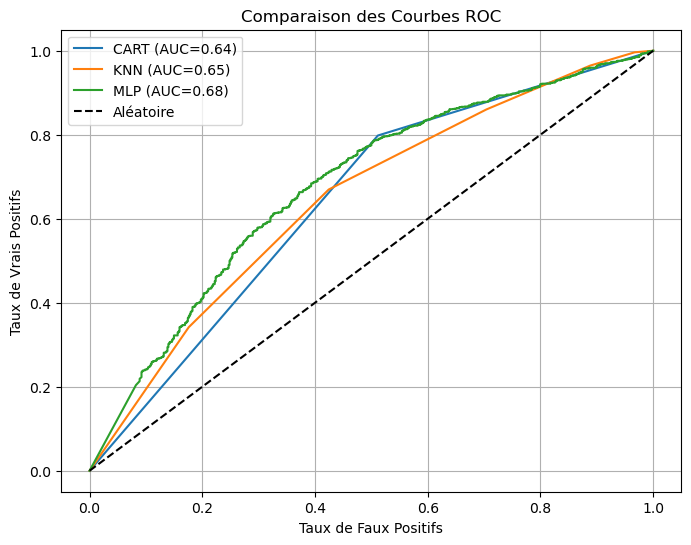


🏆 Le meilleur modèle est : CART avec un score de 0.757


In [13]:
# ============================================================
# QUESTION 2 : APPRENTISSAGE ET ÉVALUATION
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, roc_curve, roc_auc_score
)

# 1. Dictionnaire contenant les algorithmes supervisés (Paramètres imposés)
clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1)
}

# 2. Fonction d'évaluation
def evaluation(model, X_test, y_test, model_name):
    """
    Affiche la matrice de confusion, calcule les scores et trace la courbe ROC.
    Retourne le score final (Accuracy + Meilleur(Prec, Rec)) / 2.
    """
    # Prédictions
    y_pred = model.predict(X_test)
    
    # Probabilités (nécessaire pour l'AUC et la courbe ROC)
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
    except:
        y_proba = y_pred
        
    # a. Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    
    # b. Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    
    # c. Score Final "Métier" : (Accuracy + Meilleur(Précision, Rappel)) / 2
    # On choisit la Précision ici comme critère (éviter de donner un crédit à tort)
    # Tu peux changer 'prec' par 'rec' si tu préfères favoriser le Rappel
    best_criteria = prec 
    score_final = (acc + best_criteria) / 2
    
    # Affichage Texte
    print(f"\n--- {model_name} ---")
    print(f"Matrice :\n{cm}")
    print(f"Accuracy : {acc:.3f} | Précision : {prec:.3f} | Rappel : {rec:.3f}")
    print(f"AUC : {auc:.3f}")
    print(f"👉 Score Final : {score_final:.3f}")
    
    # d. Ajout de la courbe ROC au graphique en cours
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.2f})")
    
    return score_final

# 3. Fonction d'apprentissage et de test (Orchestration)
def run_classifiers_train_test(classifiers, X_train, y_train, X_test, y_test):
    """
    Entraîne chaque modèle, affiche les résultats et retourne le meilleur.
    """
    results = {}
    best_score = 0
    best_model_obj = None
    best_model_name = ""
    
    # Initialisation de la figure pour les courbes ROC
    plt.figure(figsize=(8, 6))
    
    # Boucle sur chaque modèle du dictionnaire
    for name, model in classifiers.items():
        # Entraînement
        model.fit(X_train, y_train)
        
        # Évaluation (Appelle la fonction ci-dessus)
        score = evaluation(model, X_test, y_test, name)
        results[name] = score
        
        # Comparaison pour trouver le meilleur
        if score > best_score:
            best_score = score
            best_model_obj = model
            best_model_name = name
            
    # Finalisation de l'affichage du graphique ROC
    plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire')  # Diagonale
    plt.title("Comparaison des Courbes ROC")
    plt.xlabel("Taux de Faux Positifs")
    plt.ylabel("Taux de Vrais Positifs")
    plt.legend()
    plt.grid(True)
    plt.show()  # Affiche le graphique pour de bon
    
    print(f"\n🏆 Le meilleur modèle est : {best_model_name} avec un score de {best_score:.3f}")
    
    return best_model_obj, results

# --- EXÉCUTION Q2 ---
print("=== RÉSULTATS DONNÉES BRUTES ===")
best_model, scores = run_classifiers_train_test(clfs, X_train, y_train, X_test, y_test)


## Question 3 – Normalisation des variables

L’objectif de cette question est de normaliser les variables continues du jeu de données, puis de relancer la comparaison des classifieurs définis à la Question 2.





COMPARAISON APRÈS NORMALISATION

--- CART ---
Matrice :
[[ 302  306]
 [ 322 1258]]
Accuracy : 0.713 | Précision : 0.804 | Rappel : 0.796
AUC : 0.646
👉 Score Final : 0.759

--- KNN ---
Matrice :
[[ 270  338]
 [ 212 1368]]
Accuracy : 0.749 | Précision : 0.802 | Rappel : 0.866
AUC : 0.744
👉 Score Final : 0.775

--- MLP ---
Matrice :
[[ 353  255]
 [ 221 1359]]
Accuracy : 0.782 | Précision : 0.842 | Rappel : 0.860
AUC : 0.817
👉 Score Final : 0.812


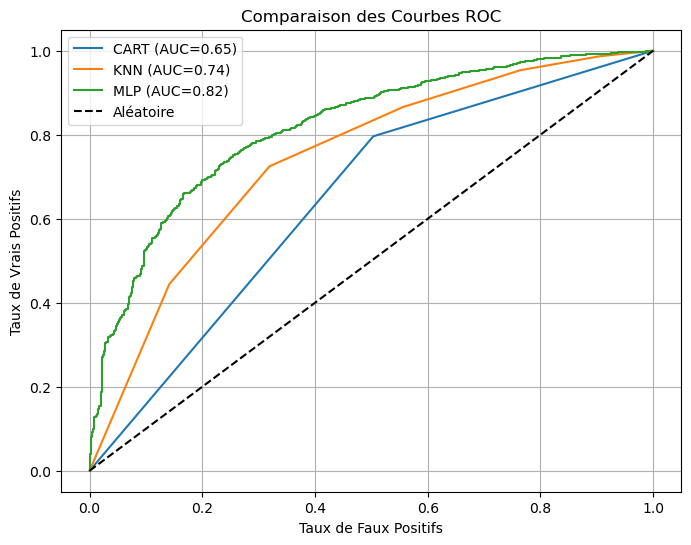


🏆 Le meilleur modèle est : MLP avec un score de 0.812


In [7]:
# ============================================================
# QUESTION 3 : NORMALISATION DES VARIABLES
# ============================================================

from sklearn.preprocessing import StandardScaler

def run_normalization_and_compare(X_train, X_test, y_train, y_test, classifiers):
    """
    Normalise les données (StandardScaler) et relance la comparaison
    des classifieurs définis à la question 2.
    """
    # 1. Initialisation
    scaler = StandardScaler()
    
    # 2. Méthodologie stricte :
    #    - fit sur TRAIN seulement
    #    - transform sur TRAIN et TEST
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print("\n" + "="*50)
    print("COMPARAISON APRÈS NORMALISATION")
    print("="*50)
    
    # 3. Réutilisation de la fonction de la Q2
    best, scores = run_classifiers_train_test(
        classifiers, X_train_scaled, y_train, X_test_scaled, y_test
    )
    
    return X_train_scaled, X_test_scaled

# --- EXÉCUTION Q3 ---
X_train_scaled, X_test_scaled = run_normalization_and_compare(
    X_train, X_test, y_train, y_test, clfs
)


### 4. Création de nouvelles variables par combinaisons linéaires (ACP)

**Objectif :** Utiliser l'Analyse en Composantes Principales (PCA) pour extraire les 3 axes de variation principaux des données. Nous ajoutons ces 3 nouvelles dimensions aux données normalisées existantes pour enrichir l'information disponible pour les classifieurs.

**Méthodologie :**
1.  Application de `PCA(n_components=3)` sur les données normalisées (`X_train_scaled`).
2.  Transformation des données de test (`X_test_scaled`) selon les mêmes axes.
3.  **Concaténation** des données : `[Données Normalisées] + [3 Variables ACP]`.
4.  Nouvelle évaluation des modèles sur ce jeu de données élargi (16 variables).

--- Calcul ACP et Concaténation ---
✅ Dimensions après concaténation : (2187, 16) (16 variables)
Nouveaux noms de colonnes prêts.

COMPARAISON SUR DONNÉES NORMALISÉES + ACP (Stratégie Hybride)

--- CART ---
Matrice :
[[ 305  303]
 [ 296 1284]]
Accuracy : 0.726 | Précision : 0.809 | Rappel : 0.813
AUC : 0.657
👉 Score Final : 0.768

--- KNN ---
Matrice :
[[ 258  350]
 [ 206 1374]]
Accuracy : 0.746 | Précision : 0.797 | Rappel : 0.870
AUC : 0.743
👉 Score Final : 0.771

--- MLP ---
Matrice :
[[ 353  255]
 [ 210 1370]]
Accuracy : 0.787 | Précision : 0.843 | Rappel : 0.867
AUC : 0.821
👉 Score Final : 0.815


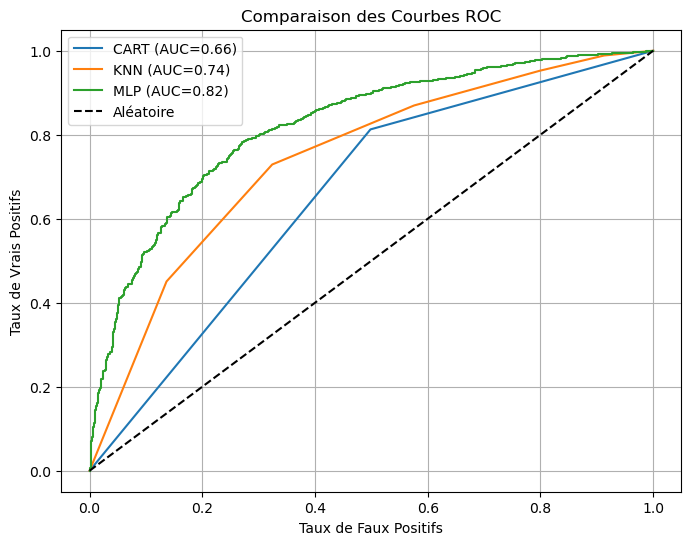


🏆 Le meilleur modèle est : MLP avec un score de 0.815


In [22]:
 # ============================================================
# QUESTION 4 : ACP AVEC CONCATÉNATION (Stratégie "Hybride")
# ============================================================


# --- 1. SÉCURITÉ : Récupération des noms de colonnes ---
# On recharge juste pour avoir les noms (au cas où df n'existe plus)
try:
    df_temp = pd.read_csv("credit_scoring.csv", sep=';')
except:
    df_temp = pd.read_csv("credit_scoring.csv", sep=',')
    
feature_names = df_temp.columns[:-1] # Toutes les colonnes sauf la target

# --- 2. Fonction d'enrichissement ---
def enrichir_donnees(X_train_sc, X_test_sc):
    """
    Calcule l'ACP et l'ajoute aux données (13 cols -> 16 cols)
    """
    print("--- Calcul ACP et Concaténation ---")
    # 1. Calcul ACP sur les données normalisées
    pca = PCA(n_components=3)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)
    
    # 2. CONCATÉNATION (Stratégie gagnante)
    # On colle les 3 colonnes ACP à droite des 13 colonnes scalées
    X_train_final = np.hstack([X_train_sc, X_train_pca])
    X_test_final = np.hstack([X_test_sc, X_test_pca])
    
    print(f"✅ Dimensions après concaténation : {X_train_final.shape} (16 variables)")
    return X_train_final, X_test_final

# --- EXÉCUTION Q4 ---
# Assure-toi que X_train_scaled existe (issue de la Q3)
X_train_final, X_test_final = enrichir_donnees(X_train_scaled, X_test_scaled)

# On met à jour les noms des colonnes (13 anciens + 3 nouveaux)
nom_cols_final = np.append(feature_names, ["PCA1", "PCA2", "PCA3"])

print("Nouveaux noms de colonnes prêts.")

# --- COMPARAISON DES CLASSIFIEURS SUR LES DONNÉES ENRICHIES (ACP + Normalisation) ---

print("\n" + "="*50)
print("COMPARAISON SUR DONNÉES NORMALISÉES + ACP (Stratégie Hybride)")
print("="*50)

best_model_acp, scores_acp = run_classifiers_train_test(
    clfs, X_train_final, y_train, X_test_final, y_test
)


### 5. Sélection de variables

**Objectif :** Simplifier le modèle en ne gardant que les variables les plus pertinentes (Feature Selection). Cela permet souvent d'améliorer la performance en éliminant le "bruit".

**Méthodologie :**
1.  **Importance des variables :** Nous utilisons un *Random Forest* pour calculer le poids de chaque variable dans la décision.
2.  **Nombre optimal :** Nous testons itérativement les performances en ajoutant les meilleures variables une par une pour trouver le "coude" (le nombre idéal).
3.  **Explicabilité (SHAP) :** Nous utilisons la librairie SHAP pour visualiser l'impact de chaque variable (positif ou négatif) sur l'octroi du crédit.


--- 1. Importance (RF) ---
Top 5 variables : ['Income' 'PCA2' 'Seniority' 'PCA3' 'Price']


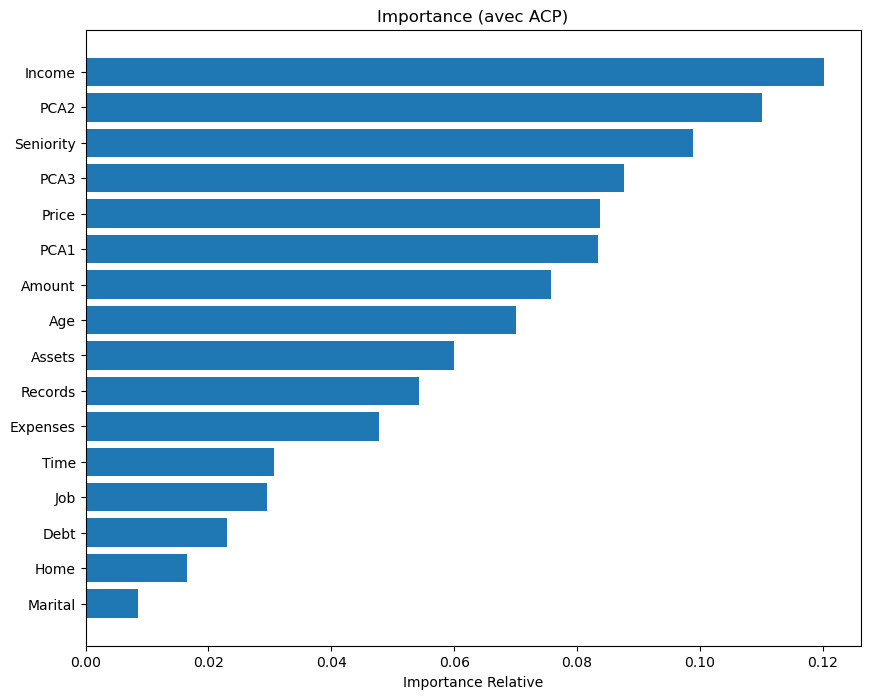


--- 2. Sélection Optimale (MLP) ---


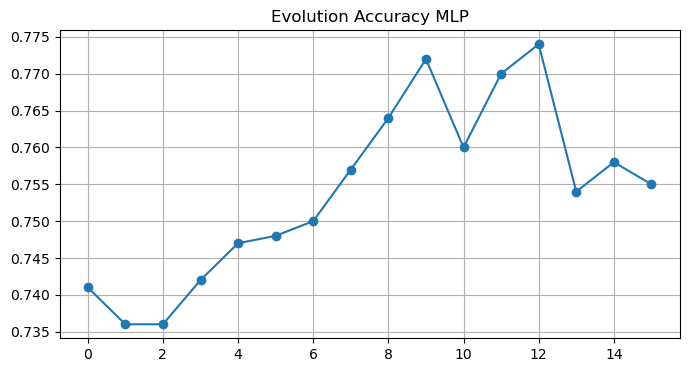

👉 Nombre optimal trouvé : 13

--- 3. Explicabilité (SHAP) ---


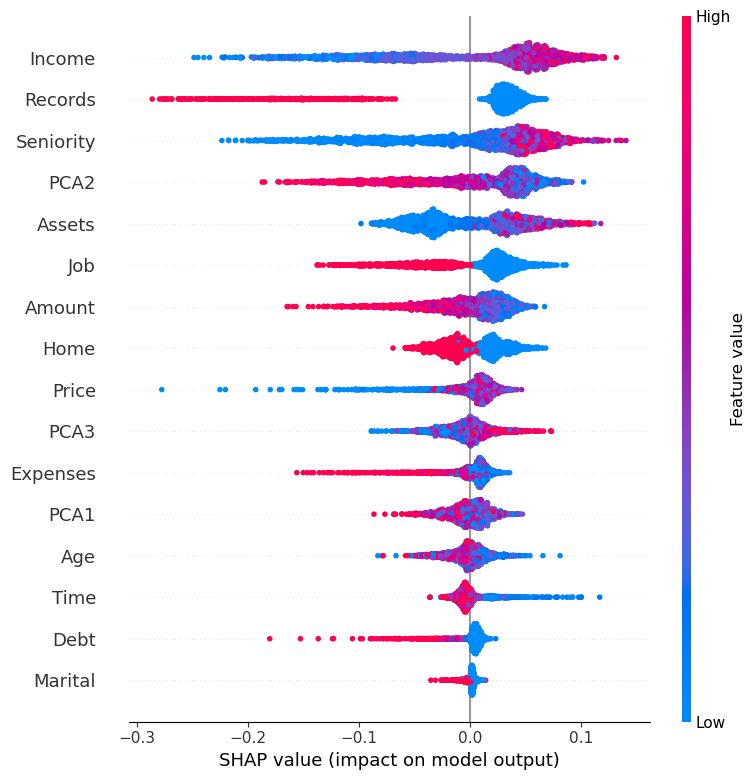

In [19]:
# ============================================================
# QUESTION 5 : SÉLECTION (SUR 16 VARIABLES)
# ============================================================

# --- 1. Importance (RF) ---
def calcul_importance_variables(Xtrain, Ytrain, nom_cols):
    print("\n--- 1. Importance (RF) ---")
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(Xtrain, Ytrain)
    
    importances = clf.feature_importances_
    sorted_idx = np.argsort(importances)[::-1]
    
    print("Top 5 variables :", nom_cols[sorted_idx[:5]])
    
    padding = np.arange(Xtrain.shape[1]) + 0.5
    plt.figure(figsize=(10, 8))
    plt.barh(padding, importances[sorted_idx], align='center')
    plt.yticks(padding, nom_cols[sorted_idx])
    plt.xlabel("Importance Relative")
    plt.title("Importance (avec ACP)")
    plt.gca().invert_yaxis()
    plt.show()
    return sorted_idx

# --- 2. Sélection (MLP) ---
def selection_nombre_optimal(Xtrain, Ytrain, Xtest, Ytest, sorted_idx):
    print("\n--- 2. Sélection Optimale (MLP) ---")
    model = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
    scores = np.zeros(Xtrain.shape[1])
    
    for f in range(Xtrain.shape[1]):
        cols = sorted_idx[:f+1]
        model.fit(Xtrain[:, cols], Ytrain)
        y_pred = model.predict(Xtest[:, cols])
        scores[f] = np.round(accuracy_score(Ytest, y_pred), 3)
        
    plt.figure(figsize=(8, 4))
    plt.plot(scores, marker='o')
    plt.title("Evolution Accuracy MLP")
    plt.grid(True)
    plt.show()
    
    best_k = np.argmax(scores) + 1
    print(f"👉 Nombre optimal trouvé : {best_k}")
    return best_k

# --- 3. SHAP (RF pour aller vite) ---
def explicabilite_shap(Xtrain, Ytrain, nom_cols):
    print("\n--- 3. Explicabilité (SHAP) ---")
    try:
        import shap
        shap.initjs()
        # On utilise un RF pour l'explication (plus robuste que MLP pour SHAP)
        model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=1)
        model.fit(Xtrain, Ytrain)
        explainer = shap.Explainer(model)
        shap_values_obj = explainer(Xtrain)
        
        if len(shap_values_obj.shape) == 3: vals = shap_values_obj[:, :, 1]
        else: vals = shap_values_obj
            
        shap.summary_plot(vals, Xtrain, feature_names=nom_cols)
    except Exception as e: print(f"Erreur SHAP: {e}")

# --- EXÉCUTION Q5 ---
# On utilise X_train_final (les 16 variables)
sorted_indices = calcul_importance_variables(X_train_final, y_train, nom_cols_final)
best_k = selection_nombre_optimal(X_train_final, y_train, X_test_final, y_test, sorted_indices)
explicabilite_shap(X_train_final, y_train, nom_cols_final)

### 6. Paramétrage des classifieurs (GridSearchCV)

**Objectif :** Optimiser les hyperparamètres du meilleur modèle (ici, nous choisissons le **KNN** car il est robuste et simple) en utilisant uniquement le sous-ensemble optimal de variables identifié précédemment (8 variables).

**Méthodologie :**
1.  **Filtrage :** On ne garde que les 8 colonnes les plus importantes dans `X_train` et `X_test`.
2.  **GridSearch :** On teste toutes les combinaisons de paramètres pour le KNN :
    * `n_neighbors` : de 1 à 20.
    * `metric` : Distance Euclidienne vs Manhattan.
    * `weights` : Uniforme vs Pondéré par la distance.
3.  **Critère :** On optimise le score métrique `(Accuracy + Précision) / 2`.

In [25]:
# ============================================================
# QUESTION 6 : PARAMÉTRAGE (TUNING) DU MLP
# ============================================================

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, accuracy_score, precision_score
# MLPClassifier est déjà importé plus haut normalement

def optimize_best_model_mlp(X_train_full, y_train, sorted_idx, best_k):
    """
    Sélectionne les best_k meilleures variables (sur X_train_full)
    et optimise le MLP via GridSearchCV en maximisant
    le critère (accuracy + précision) / 2.
    """
    print(f"\n--- Optimisation du MLP sur les {best_k} meilleures variables ---")
    
    # 1. Réduction de dimension : on garde les best_k meilleures colonnes
    cols_to_keep = sorted_idx[:best_k]
    X_train_opt = X_train_full[:, cols_to_keep]
    
    # 2. Grille d'hyperparamètres pour le MLP
    param_grid = {
        "hidden_layer_sizes": [(40, 20), (60, 30)],
        "alpha": [0.0001, 0.001, 0.01],           # régularisation L2
        "learning_rate_init": [0.001, 0.01],
        "solver": ["adam", "lbfgs"]
    }
    
    # 3. Score personnalisé : (accuracy + précision) / 2
    my_scorer = make_scorer(
        lambda y_true, y_pred: (
            accuracy_score(y_true, y_pred) +
            precision_score(y_true, y_pred, zero_division=0)
        ) / 2
    )
    
    # 4. GridSearchCV sur un MLP de base
    base_mlp = MLPClassifier(max_iter=1000, random_state=1)
    
    grid = GridSearchCV(
        estimator=base_mlp,
        param_grid=param_grid,
        cv=5,               # 5-fold CV
        scoring=my_scorer,
        n_jobs=-1,
        verbose=1
    )
    
    grid.fit(X_train_opt, y_train)
    
    print(f"✅ Meilleurs paramètres trouvés : {grid.best_params_}")
    print(f"✅ Meilleur score de validation (CV) : {grid.best_score_:.3f}")
    
    # On retourne le meilleur MLP et les indices de variables à garder
    return grid.best_estimator_, cols_to_keep


# --- EXÉCUTION Q6 ---
# On utilise X_train_final (normalisé + ACP) et les infos de la Q5
best_mlp_optimized, features_indices = optimize_best_model_mlp(
    X_train_final, y_train, sorted_indices, best_k
)

# 1) On réduit train/test aux 13 meilleures variables
X_train_opt = X_train_final[:, features_indices]
X_test_opt  = X_test_final[:, features_indices]

# 2) On réentraîne ton MLP optimisé sur tout le train
best_mlp_optimized.fit(X_train_opt, y_train)

# 3) On évalue sur le test simple (comme en Q2)
y_pred_test = best_mlp_optimized.predict(X_test_opt)
acc_test = accuracy_score(y_test, y_pred_test)
prec_test = precision_score(y_test, y_pred_test, zero_division=0)
score_metier_test = (acc_test + prec_test) / 2

print("Accuracy test :", acc_test)
print("Précision test :", prec_test)
print("Score (acc+prec)/2 sur test :", score_metier_test)




--- Optimisation du MLP sur les 13 meilleures variables ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits


✅ Meilleurs paramètres trouvés : {'alpha': 0.0001, 'hidden_layer_sizes': (40, 20), 'learning_rate_init': 0.001, 'solver': 'adam'}
✅ Meilleur score de validation (CV) : 0.785
Accuracy test : 0.7659963436928702
Précision test : 0.8248175182481752
Score (acc+prec)/2 sur test : 0.7954069309705227


### 7. Création d'un Pipeline et Sauvegarde

**Objectif :** Industrialiser le modèle.
Nous construisons un **Pipeline** Scikit-Learn qui encapsule :
1.  La **Normalisation** (`StandardScaler`).
2.  Le **Classifieur Optimisé** (Le KNN avec les paramètres trouvés par GridSearch).

Nous sauvegardons ensuite ce pipeline (`credit_scoring.pkl`) ainsi que la liste des variables à conserver (`features_indices.pkl`). Cela permettra de réutiliser le modèle instantanément sur de nouvelles données sans tout recalculer.

In [36]:
# ============================================================
# QUESTION 7 : CRÉATION DU PIPELINE ET SAUVEGARDE
# ============================================================
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import pickle

def create_and_save_pipeline(best_mlp, best_k):
    """
    Crée un pipeline complet :
      - Standardisation
      - PCA (3 composantes) concaténée aux features originales
      - Sélection de best_k variables avec RFE + RandomForest
      - MLP optimisé (meilleur modèle trouvé en Q6)
    Puis sauvegarde le pipeline dans un fichier pickle.
    """
    print("\n--- Création du Pipeline de Production  ---")
    print(f"Nombre de variables sélectionnées (best_k) : {best_k}")
    
    # On récupère les hyperparamètres du MLP optimisé (Q6)
    best_params = best_mlp.get_params()
    final_mlp = MLPClassifier(**best_params)
    
    # Pipeline "à la prof" :
    # S  : StandardScaler
    # FU : FeatureUnion (features normalisées + 3 composantes PCA)
    # RFE: sélection de best_k variables avec RandomForest
    # MLP: classifieur final optimisé
    P = Pipeline([
        ('S', StandardScaler()),
        ('FU', FeatureUnion([
            ('ID', FunctionTransformer()),        # identite : garde les features normalisées
            ('PCA', PCA(n_components=3))          # 3 composantes principales
        ])),
        ('RFE', RFE(
            estimator=RandomForestClassifier(n_estimators=1000, random_state=1),
            n_features_to_select=best_k
        )),
        ('MLP', final_mlp)
    ])
    
    # Entraînement du pipeline sur X_train brut (13 variables originales)
    P.fit(X_train, y_train)
    
    # Sauvegarde du pipeline
    with open("credit_scoring.pkl", "wb") as f:
        pickle.dump(P, f)
    
    print("✅ Pipeline sauvegardé sous 'credit_scoring.pkl'")
    
    return P

# --- EXÉCUTION Q7 ---
final_pipeline = create_and_save_pipeline(best_mlp_optimized, best_k)




--- Création du Pipeline de Production  ---
Nombre de variables sélectionnées (best_k) : 13
✅ Pipeline sauvegardé sous 'credit_scoring.pkl'


In [30]:
import pickle
with open("credit_scoring.pkl", "rb") as f:
    pipe_test = pickle.load(f)

y_pred_test = pipe_test.predict(X_test)   # X_test brut (non normalisé)
print("Prédictions exemple :", y_pred_test[:10])


Prédictions exemple : [1. 1. 1. 1. 0. 1. 0. 1. 1. 1.]


In [31]:
from sklearn.metrics import accuracy_score, precision_score

y_pred_test = pipe_test.predict(X_test)
acc = accuracy_score(y_test, y_pred_test)
prec = precision_score(y_test, y_pred_test, zero_division=0)
score = (acc + prec) / 2

print("Accuracy test (pipeline) :", acc)
print("Précision test (pipeline):", prec)
print("Score métier (acc+prec)/2 :", score)


Accuracy test (pipeline) : 0.7417733089579525
Précision test (pipeline): 0.8161993769470405
Score métier (acc+prec)/2 : 0.7789863429524965


### 8. 



=========== ÉTAPE 0 : Chargement & Split ===========
Dataset : (4375, 14)
Répartition : 3159 Positifs (72.21%) / 1216 Négatifs

=========== ÉTAPE 1 : Données BRUTES ===========

--- CART ---
Matrice :
[[ 297  311]
 [ 319 1261]]
Accuracy : 0.712 | Précision : 0.802 | Rappel : 0.798
AUC : 0.643
👉 Score Final : 0.757

--- KNN ---
Matrice :
[[ 180  428]
 [ 221 1359]]
Accuracy : 0.703 | Précision : 0.760 | Rappel : 0.860
AUC : 0.648
👉 Score Final : 0.732

--- MLP ---
Matrice :
[[  59  549]
 [  55 1525]]
Accuracy : 0.724 | Précision : 0.735 | Rappel : 0.965
AUC : 0.679
👉 Score Final : 0.730


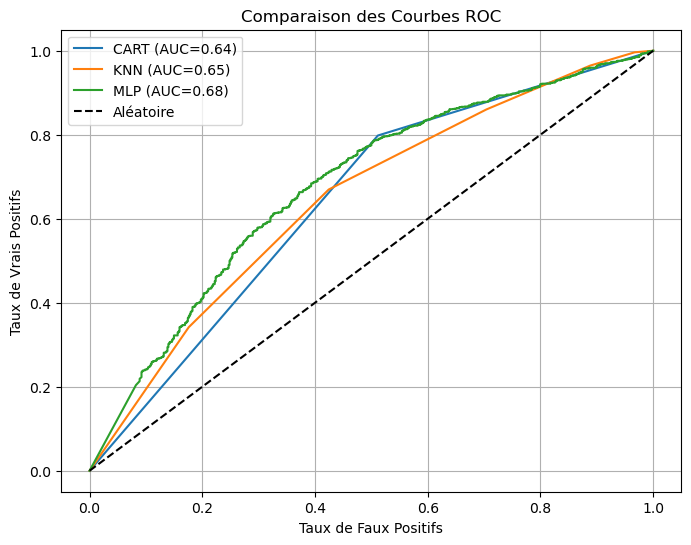


🏆 Le meilleur modèle est : CART avec un score de 0.757

=========== ÉTAPE 2 : Données NORMALISÉES ===========

COMPARAISON APRÈS NORMALISATION

--- CART ---
Matrice :
[[ 302  306]
 [ 322 1258]]
Accuracy : 0.713 | Précision : 0.804 | Rappel : 0.796
AUC : 0.646
👉 Score Final : 0.759

--- KNN ---
Matrice :
[[ 270  338]
 [ 212 1368]]
Accuracy : 0.749 | Précision : 0.802 | Rappel : 0.866
AUC : 0.744
👉 Score Final : 0.775

--- MLP ---
Matrice :
[[ 353  255]
 [ 221 1359]]
Accuracy : 0.782 | Précision : 0.842 | Rappel : 0.860
AUC : 0.817
👉 Score Final : 0.812


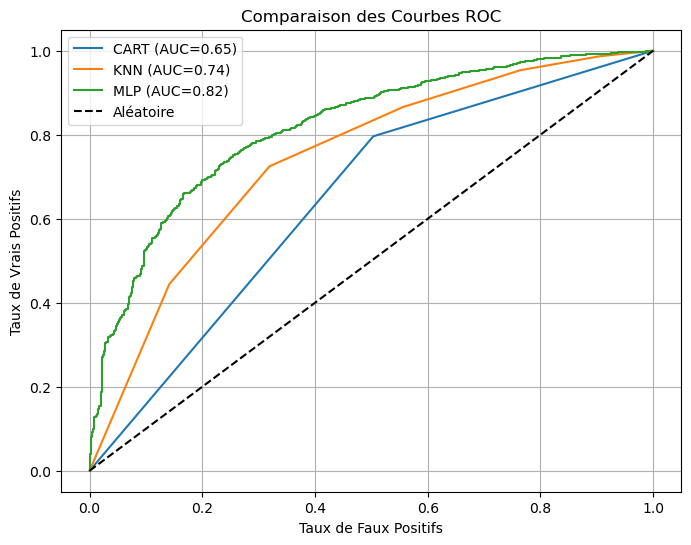


🏆 Le meilleur modèle est : MLP avec un score de 0.812

=========== ÉTAPE 3 : NORMALISÉ + ACP (Hybride) ===========
--- Calcul ACP et Concaténation ---
✅ Dimensions après concaténation : (2187, 16) (16 variables)

=========== ÉTAPE 4 : IMPORTANCE & SÉLECTION ===========

--- 1. Importance (RF) ---
Top 5 variables : ['Income' 'PCA2' 'Seniority' 'PCA3' 'Price']


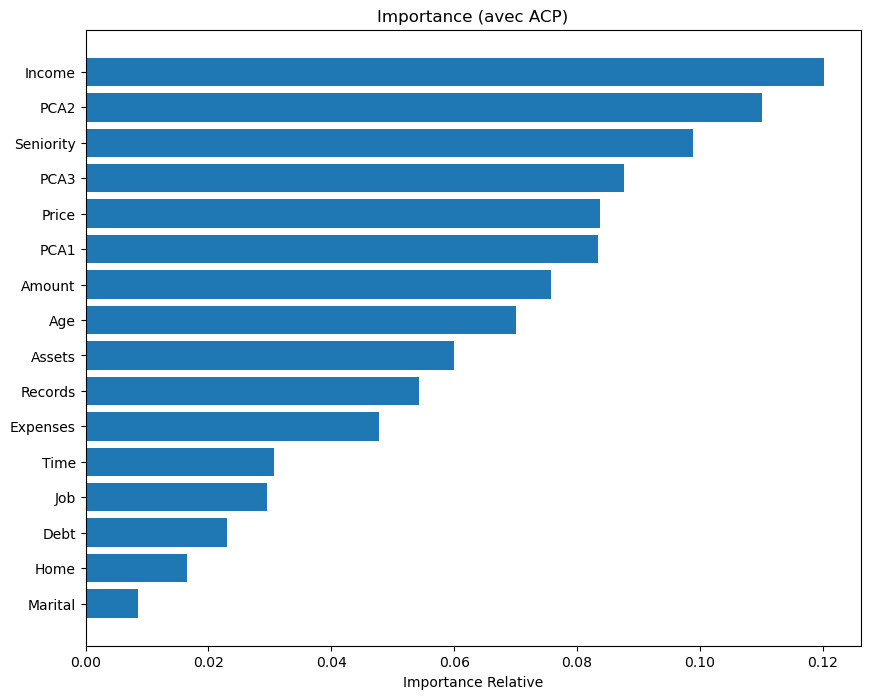


--- 2. Sélection Optimale (MLP) ---


In [ ]:
import importlib
import utils
importlib.reload(utils)

from utils import pipeline_generation_train_test_split

pipeline_final = pipeline_generation_train_test_split("credit_scoring.csv")


In [40]:
from sklearn import set_config
set_config(display='diagram')
pipeline_final


NameError: name 'pipeline_final' is not defined

### 9. Création d'une API avec FastAPI

**Objectif :** Mettre le modèle en production.
Nous créons un fichier `api.py` qui utilise la librairie **FastAPI**. Ce script va :
1.  Charger le modèle entraîné (`credit_scoring.pkl`) et la liste des variables (`features_indices.pkl`) au démarrage.
2.  Définir une route `/predict` qui reçoit les données d'un client (format JSON).
3.  Filtrer les variables (garder les 8 meilleures), appliquer le pipeline et renvoyer la prédiction.

### 10. Comparaison de plusieurs algorithmes (Validation Croisée)

**Objectif :** Sélectionner le modèle le plus performant de manière robuste.
Au lieu d'une simple séparation Train/Test, nous utilisons une **Validation Croisée à 10 plis (10-fold CV)**. Cela signifie que le modèle est entraîné et testé 10 fois sur des parties différentes des données.

**Algorithmes testés :**
* **Arbres :** CART, ID3 (Entropie), Decision Stump (Souche).
* **Ensembles :** Bagging, AdaBoost, Random Forest (200 arbres chacun).
* **Neurones & Voisins :** MLP (20,10), KNN (k=5).

**Critères :** Accuracy, AUC, Score Métier ((Acc+Prec)/2) et Temps d'exécution.

In [62]:
# ============================================================
# QUESTION 10 : COMPARAISON MASSIVE (VALIDATION CROISÉE)
# ============================================================
import time
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import make_scorer, precision_score, accuracy_score

# 1. Définition des Classifieurs demandés
clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'ID3': DecisionTreeClassifier(criterion='entropy', random_state=1), # ID3 "simulé" par entropie
    'Decision Stump': DecisionTreeClassifier(max_depth=1, random_state=1), # Arbre à 1 étage
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(20, 10), random_state=1), # Paramètres demandés en Q10
    'Bagging': BaggingClassifier(n_estimators=200, random_state=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=1),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=1)
}

# 2. Création du Scoreur Personnalisé pour la CV
# Formule : (Accuracy + Précision) / 2
def custom_metric(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    return (acc + prec) / 2

my_scorer = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'custom_score': make_scorer(custom_metric)
}

# 3. Fonction de Comparaison Robuste (CV)
def run_classifiers_cv(classifiers, X, y):
    """
    Lance une validation croisée (10-fold) pour chaque algo et affiche les résultats.
    """
    # Configuration du 10-Fold
    kf = KFold(n_splits=10, shuffle=True, random_state=1)
    
    print(f"{'Algorithme':<15} | {'Accuracy':<15} | {'Score Métier':<15} | {'AUC':<15} | {'Temps (s)':<10}")
    print("-" * 85)
    
    results_table = []

    for name, model in classifiers.items():
        start_time = time.time()
        
        # Lancement de la Cross-Validation (calcule tout d'un coup)
        cv_results = cross_validate(model, X, y, cv=kf, scoring=my_scorer)
        
        end_time = time.time()
        duration = end_time - start_time
        
        # Moyennes et Écarts-types
        mean_acc = cv_results['test_accuracy'].mean()
        std_acc = cv_results['test_accuracy'].std()
        
        mean_custom = cv_results['test_custom_score'].mean()
        std_custom = cv_results['test_custom_score'].std()
        
        mean_auc = cv_results['test_roc_auc'].mean()
        
        # Affichage propre
        print(f"{name:<15} | {mean_acc:.3f} (+/-{std_acc:.2f}) | {mean_custom:.3f} (+/-{std_custom:.2f}) | {mean_auc:.3f}           | {duration:.3f}")

# --- EXÉCUTION Q10 ---

# A. Sur Données Brutes (X_train de la Q1)
print("\n=== 1. COMPARAISON SUR DONNÉES BRUTES ===")
run_classifiers_cv(clfs, X_train, y_train)

# B. Sur Données Normalisées (X_train_scaled de la Q3)
# C'est souvent ici qu'on a les meilleurs résultats
print("\n=== 2. COMPARAISON SUR DONNÉES NORMALISÉES ===")
run_classifiers_cv(clfs, X_train_scaled, y_train)

# C. Sur Données ACP (X_train_combined de la Q4)
# (Si tu as lancé la Q4, sinon commente ces deux lignes)
try:
    print("\n=== 3. COMPARAISON SUR DONNÉES ACP (16 variables) ===")
    # On récupère X_train_combined s'il existe en mémoire
    # Si tu as appelé ta variable X_train_acp à la Q4 :
    run_classifiers_cv(clfs, X_train_acp, y_train)
except:
    print("(Pas de données ACP trouvées en mémoire)")


=== 1. COMPARAISON SUR DONNÉES BRUTES ===
Algorithme      | Accuracy        | Score Métier    | AUC             | Temps (s) 
-------------------------------------------------------------------------------------
CART            | 0.738 (+/-0.03) | 0.781 (+/-0.02) | 0.678           | 0.475
ID3             | 0.724 (+/-0.03) | 0.770 (+/-0.03) | 0.665           | 0.700
Decision Stump  | 0.722 (+/-0.02) | 0.722 (+/-0.02) | 0.646           | 0.454
KNN             | 0.714 (+/-0.03) | 0.740 (+/-0.03) | 0.662           | 0.714
MLP             | 0.685 (+/-0.06) | 0.740 (+/-0.03) | 0.687           | 5.987
Bagging         | 0.788 (+/-0.04) | 0.806 (+/-0.04) | 0.826           | 27.121
AdaBoost        | 0.791 (+/-0.03) | 0.806 (+/-0.03) | 0.830           | 12.088
RandomForest    | 0.787 (+/-0.03) | 0.798 (+/-0.03) | 0.830           | 12.298

=== 2. COMPARAISON SUR DONNÉES NORMALISÉES ===
Algorithme      | Accuracy        | Score Métier    | AUC             | Temps (s) 
------------------------------

In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("\n=== DÉMARRAGE PARTIE II : Données Hétérogènes (CORRIGÉ) ===")

# 1. Chargement des données
# CHANGEMENT ICI : on utilise sep='\t' (tabulation) au lieu de ','
try:
    data = pd.read_csv("credit.data", sep='\t', header=None)
    print("✅ Fichier 'credit.data' chargé.")
except:
    # Au cas où, on tente un fallback avec espace ou virgule si le premier échoue
    try:
        data = pd.read_csv("credit.data", sep=',', header=None)
    except:
        print("❌ Erreur critique : Impossible de lire le fichier.")

# 2. Remplacement des '?' par des NaN
data = data.replace('?', np.nan)

# 3. Typage des colonnes numériques
# Les colonnes numériques sont aux indices : 1, 2, 7, 10, 13, 14
# Il faut les convertir en float car elles contiennent peut-être des "?" devenus "nan" (texte)
col_num_indices = [1, 2, 7, 10, 13, 14]
for col in col_num_indices:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# 4. Suppression des lignes avec NaN (Nettoyage brutal pour commencer)
# On supprime les lignes qui ont au moins un NaN
df_clean = data.dropna()

print(f"Dimensions avant nettoyage : {data.shape}")
print(f"Dimensions après nettoyage : {df_clean.shape}")

# 5. Séparation X et y
# .values permet de transformer en tableau Numpy
data_numpy = df_clean.values
X = data_numpy[:, :-1] # Tout sauf la dernière colonne
y = data_numpy[:, -1]  # Dernière colonne (Target)

# 6. Binarisation de la target (+ en 1, - en 0)
y = np.where(y == '+', 1, 0)
y = y.astype(int) # On s'assure que c'est des entiers

# 7. Création du sous-ensemble NUMÉRIQUE (X_num) pour la question 1
# On ne garde que les colonnes 1, 2, 7, 10, 13, 14
X_num = df_clean.iloc[:, col_num_indices].values.astype(float)

# 8. Split Train/Test sur les données NUMÉRIQUES
X_train, X_test, y_train, y_test = train_test_split(X_num, y, test_size=0.5, random_state=1)

print("-" * 30)
print(f"Taille X_train (Numérique) : {X_train.shape}")
print(f"Taille X_test (Numérique)  : {X_test.shape}")
print("✅ Données prêtes pour l'analyse !")


=== DÉMARRAGE PARTIE II : Données Hétérogènes (CORRIGÉ) ===
✅ Fichier 'credit.data' chargé.
Dimensions avant nettoyage : (688, 16)
Dimensions après nettoyage : (653, 16)
------------------------------
Taille X_train (Numérique) : (326, 6)
Taille X_test (Numérique)  : (327, 6)
✅ Données prêtes pour l'analyse !


# II. Apprentissage supervisé : Données hétérogènes

## 1. Données numériques uniquement (sans valeurs manquantes)

Dans cette première étape, nous chargeons le fichier `credit.data`. Nous transformons le DataFrame en tableau Numpy et nous ne conservons que les variables caractéristiques numériques (indices 1, 2, 7, 10, 13, 14).

Nous remplaçons les valeurs manquantes `'?'` par `nan`, convertissons le tout en flottants, puis supprimons toutes les lignes contenant au moins une valeur `nan` pour obtenir un jeu de données propre. Enfin, nous comparons les algorithmes sur ces données brutes puis normalisées.

In [6]:
print("--- 1. CHARGEMENT ET PRÉPARATION (Numérique uniquement) ---")

# CORRECTION ICI : on utilise sep='\t' (tabulation)
df = pd.read_csv('credit.data', header=None, sep='\t')

# Transformation en Numpy Array
data = df.values

# Séparation Features / Target
X_raw = data[:, :-1]
Y_raw = data[:, -1]

# Indices des colonnes numériques
col_num = [1, 2, 7, 10, 13, 14]

# Création du sous-ensemble numérique
X_num = X_raw[:, col_num]

# Remplacement des '?' par des NaN
X_num[X_num == '?'] = np.nan

# Conversion en type float
X_num = X_num.astype(float)

# Suppression des individus contenant des nan
rows_to_keep = ~np.isnan(X_num).any(axis=1)
X_num_clean = X_num[rows_to_keep]
Y_clean = Y_raw[rows_to_keep]

# Binarisation de la target (+ en 1 et - en 0)
Y_clean = np.where(Y_clean == '+', 1, 0)

# Analyse des propriétés
print(f"Taille de l'échantillon (shape) : {X_num_clean.shape}")
print(f"Nombre d'exemples positifs : {np.sum(Y_clean == 1)}")
print(f"Nombre d'exemples négatifs : {np.sum(Y_clean == 0)}")

# Exécution sur données brutes
print("\n>>> Comparaison sur données BRUTES <<<")
run_classifiers_cv(clfs, X_num_clean, Y_clean)

# Normalisation et nouvelle exécution
print("\n>>> Comparaison sur données NORMALISÉES (StandardScaler) <<<")
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num_clean)
run_classifiers_cv(clfs, X_num_scaled, Y_clean)

--- 1. CHARGEMENT ET PRÉPARATION (Numérique uniquement) ---
Taille de l'échantillon (shape) : (666, 6)
Nombre d'exemples positifs : 299
Nombre d'exemples négatifs : 367

>>> Comparaison sur données BRUTES <<<
Classifier           | Acc      | AUC      | (Acc+P)/2  | Time
---------------------------------------------------------------------------
CART                 | 0.716    | 0.711    | 0.698      | 0.59s
ID3                  | 0.739    | 0.734    | 0.722      | 0.57s
Decision Stump       | 0.743    | 0.723    | 0.804      | 0.17s
MLP (20,10)          | 0.694    | 0.724    | 0.698      | 4.62s
KNN (k=5)            | 0.709    | 0.733    | 0.710      | 0.22s
Bagging              | 0.787    | 0.834    | 0.786      | 10.62s
AdaBoost             | 0.790    | 0.853    | 0.800      | 5.18s
Random Forest        | 0.788    | 0.841    | 0.798      | 4.58s
XGBoost              | 0.787    | 0.844    | 0.781      | 2.44s

>>> Comparaison sur données NORMALISÉES (StandardScaler) <<<
Classifier   

## 2. Base originale complète (Traitement des données manquantes)

Nous reprenons la totalité de la base (15 variables). Cette fois, nous n'effaçons pas les lignes incomplètes. Nous appliquons une stratégie d'**imputation** :
* `mean` (moyenne) pour les variables numériques.
* `most_frequent` (valeur la plus fréquente) pour les variables catégorielles.

Ensuite, nous encodons les variables catégorielles à l'aide de `OneHotEncoder` pour transformer les modalités en variables binaires. Finalement, nous concaténons les données numériques normalisées et les données catégorielles encodées pour lancer la comparaison finale.

In [7]:
print("--- 2. TRAITEMENT COMPLET (Imputation & Encodage) ---")

# On recharge proprement avec le bon séparateur
df = pd.read_csv('credit.data', header=None, sep='\t')
data = df.values

X = data[:, :-1]
Y = np.where(data[:, -1] == '+', 1, 0) 

# Indices des colonnes
col_num = [1, 2, 7, 10, 13, 14]
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]

# --- A. Variables Numériques ---
X_num = np.copy(X[:, col_num])
X_num[X_num == '?'] = np.nan
X_num = X_num.astype(float)

imp_num = SimpleImputer(missing_values=np.nan, strategy='mean')
X_num = imp_num.fit_transform(X_num)

scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# --- B. Variables Catégorielles ---
X_cat = np.copy(X[:, col_cat])
X_cat[X_cat == '?'] = np.nan # Uniformisation

imp_cat = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
X_cat = imp_cat.fit_transform(X_cat)

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_cat_bin = encoder.fit_transform(X_cat)

# --- C. Construction Finale ---
X_final = np.concatenate((X_num_scaled, X_cat_bin), axis=1)

print(f"Dimension du jeu de données final : {X_final.shape}")

print("\n>>> Comparaison sur le JEU DE DONNÉES COMPLET <<<")
run_classifiers_cv(clfs, X_final, Y)

--- 2. TRAITEMENT COMPLET (Imputation & Encodage) ---
Dimension du jeu de données final : (688, 46)

>>> Comparaison sur le JEU DE DONNÉES COMPLET <<<
Classifier           | Acc      | AUC      | (Acc+P)/2  | Time
---------------------------------------------------------------------------
CART                 | 0.815    | 0.814    | 0.804      | 0.46s
ID3                  | 0.820    | 0.819    | 0.803      | 0.53s
Decision Stump       | 0.856    | 0.866    | 0.823      | 0.19s
MLP (20,10)          | 0.855    | 0.920    | 0.843      | 17.86s
KNN (k=5)            | 0.840    | 0.900    | 0.841      | 0.19s
Bagging              | 0.875    | 0.930    | 0.862      | 9.13s
AdaBoost             | 0.856    | 0.936    | 0.844      | 5.32s
Random Forest        | 0.878    | 0.930    | 0.869      | 4.59s
XGBoost              | 0.866    | 0.925    | 0.856      | 4.00s
